# Steering CPGs towards a moving target

Can a CPG that walks the gecko in a straight line learn to walk towards a
target, and follow it when it moves? Every CPG takes an input vector `u`
through `set_input(u)`. Each entry of `u` goes to a handle of every joint
times a weight of its own, from the parameter group `input_weights`; the
slow handles change the gait through a filter that settles in about 0.5 s.

The task:

* Body and world: `gecko()` in `SimpleFlatWorld`, as in `cpg_locomotion`,
  plus a small red marker on the current target that nothing touches.
* A trial lasts 30 s. Target A lies on a circle of radius R = 1.0 m
  around the core's start position; at 15 s the target jumps to B, also on
  the circle. On the DSS-M15 hinges the best straight gaits walk 0.50 to
  2.44 m in 10 s, so five of the seven can reach A in 15 s and the two
  Tegotae gaits can only head for it. Nothing tells a CPG to stop, so a
  smaller circle (the first run used 0.3 m) mostly measures how far a gait
  overshoots; at 1 m the score mostly measures heading.
* Features, computed every control call (15 ms): `u` = (distance to the
  target, capped at 1 m; sin and cos of the bearing), the bearing being the
  angle from the core's local x axis to the target, in the floor plane.
* Routes: the distance drives the `frequency` handle; the sine and the
  cosine of the bearing each drive both `offset` and `amplitude`, so a gait
  can turn by bending and by uneven strides. One weight per joint per route:
  5 x 8 = 40 weights.
* Score of a trial: the mean distance to the current target over the 30 s,
  in metres (lower is better). A gecko that stands still scores R, and one
  that walks straight away from both targets scores more, so only a score
  below R shows that a gait goes to the target.

Each CPG starts from the best straight gait `cpg_locomotion` found for it
(copied below, from its run of 2026-10-22 on the DSS-M15 hinges, commit
`3b81ebc`), with every weight at 0, which is that gait unchanged. CMA-ES then
searches the gait and the 40 weights together for 200 trials, each number
scaled to its own range (the gait's from the CPG's parameter ranges, the
weights from -1 to 1), as `cpg_locomotion` does. Each trial runs two target
pairs: random angles (a, b) for A and B, and the pair turned by half a turn,
so the weights are always scored on targets in opposite directions. Every CPG
sees the same sequence of pairs.

The test uses 10 fresh pairs no search saw, and runs every CPG with
the gait and weights its search found (steered) and with its starting gait
unsteered. The
baseline is the unsteered `PhaseCPG`, the best straight walker. The two best
gaits, steered and baseline, are filmed from above on the first test pair
into `__data__/cpg_steering/` (run in place from `tests/functional` to keep
the files: `cd tests/functional && uv run --no-sync jupyter execute --inplace
cpg_steering.ipynb`).

The notebook is marked slow (about 61 minutes); `tools/run_notebooks.py`
runs it only with `--slow` or when named.

In [1]:
from ariel.rendering import (  # chooses the OpenGL backend before MuJoCo loads
    VideoRecorder,
)

In [2]:
# Standard library
import os
import time
from itertools import starmap

# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import nevergrad as ng
import numpy as np
from rich.console import Console

# Local libraries
from ariel import DATA
from ariel.body_phenotypes.robogen_lite.prebuilt_robots.gecko import gecko
from ariel.parameters import FrozenModel
from ariel.simulation import (
    AdaptiveHopfCPG,
    Controller,
    HopfCPG,
    InputRoute,
    LearnableTegotaeCPG,
    NaCPG,
    PhaseCPG,
    SimpleFlatWorld,
    SwingStanceCPG,
    TegotaeCPG,
    Tracker,
    create_fully_connected_adjacency,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 50  # keeps the notebook under 500 KB
console = Console()

MODELS = [
    HopfCPG,
    AdaptiveHopfCPG,
    PhaseCPG,
    SwingStanceCPG,
    NaCPG,
    TegotaeCPG,
    LearnableTegotaeCPG,
]
CLASSES = {cpg_class.__name__: cpg_class for cpg_class in MODELS}
BASELINE = "PhaseCPG"
RADIUS = 1.0  # metres
SWITCH = 15.0  # seconds
SECONDS = 30.0
STRAIGHT_SECONDS = 10.0  # the trial length of cpg_locomotion
STEPS_PER_CONTROL = 4
BUDGET = 200
TEST_PAIRS = 10
STEERING = [
    InputRoute(handle="frequency"),  # u[0], distance to the target
    InputRoute(handle="offset"),  # u[1], sin of the bearing
    InputRoute(handle="amplitude"),  # u[2], cos of the bearing
    InputRoute(handle="amplitude"),  # u[3], sin of the bearing again
    InputRoute(handle="offset"),  # u[4], cos of the bearing again
]
# Set by ariel.rendering's probe only when a backend works (or by the user)
BACKEND = os.environ.get("MUJOCO_GL")

## The starting gaits

The best parameters `cpg_locomotion` found for each CPG, and the distance
each walked in 10 s. The checks at the end replay each one for 10 s here and
expect the same distance.

In [3]:
class Gait(FrozenModel):
    """A straight gait found by cpg_locomotion."""

    distance: float
    params: list[float]


GAITS = {
    "HopfCPG": Gait(
        distance=1.596380749676154,
        params=[
            3.5934945009877945,
            4.791027587332674,
            3.3306577164709914,
            2.683533651296673,
            5.90364360886716,
            3.978223956515163,
            3.0291696174360507,
            3.466777177843176,
            10.305666732784134,
            9.016127315441874,
            8.054759965778187,
            4.837058934321233,
            11.356219183101901,
            1.9589641478025874,
            4.847213633392533,
            1.4027781835511155,
            0.17118109832112013,
            0.11170044907134431,
            0.9804975746553244,
            1.1667661197335455,
            0.8056931912389254,
            1.4766508900016198,
            0.6885724909975155,
            0.8579902934250743,
            0.14625866291464518,
            -0.27244094359598964,
            -0.29948880172165426,
            0.49780695854226353,
            -0.2243492480903797,
            0.14070738313867692,
            0.0691343296087441,
            0.4617937916851609,
        ],
    ),
    "AdaptiveHopfCPG": Gait(
        distance=2.0807676869595064,
        params=[
            1.5377343556001635,
            6.07865363522603,
            5.466052951848146,
            1.4265020452404935,
            4.9564612197344475,
            4.75455734996536,
            2.249226460605037,
            1.8639636820360674,
            9.121342701241424,
            9.433452260183003,
            8.754989557751436,
            4.680905067916842,
            8.417953519576107,
            0.2146264695307074,
            4.132389098168633,
            2.067793583492036,
            0.01001132586365862,
            0.4519329784631596,
            1.0987152280924941,
            1.188712202316452,
            0.9216119118986499,
            1.3640196091369934,
            0.8067718575203987,
            0.937233682363278,
            0.16224501947316572,
            -0.30184697709940916,
            -0.23302637956351008,
            0.3165423106949624,
            -0.09133127606583158,
            0.2626603172394515,
            0.20311044069767337,
            0.3596565799403608,
        ],
    ),
    "PhaseCPG": Gait(
        distance=2.439762899408016,
        params=[
            2.751735261353428,
            6.215340343220078,
            5.556191924553975,
            1.8492441716077392,
            4.686047639390352,
            4.612207428077248,
            1.8464395860823404,
            2.5108100054803746,
            10.930232458056388,
            9.375174251009215,
            8.77832507931334,
            6.364745150089903,
            7.881603200481355,
            1.7940179703670567,
            4.978076593632627,
            1.061928070510141,
            0.07121294236914212,
            0.5183840467634308,
            1.0809107887235883,
            1.3017132840744965,
            0.8486451431459087,
            1.5385493503471535,
            0.6137673756885849,
            1.070874846863231,
            0.004863193570142421,
            -0.31032766430132586,
            -0.18225434886292702,
            0.375861175502577,
            0.00948019945742129,
            0.2640788059919923,
            0.13268655283122766,
            0.21906145125800958,
        ],
    ),
    "SwingStanceCPG": Gait(
        distance=1.0056787266892406,
        params=[
            2.7260961420274663,
            5.920790675574273,
            2.5319615871147185,
            1.6702897582589702,
            2.2536683070445345,
            4.7363205340835774,
            5.4294937428577885,
            0.9111000567266094,
            10.089857019736671,
            9.032152574678598,
            2.5759872269473845,
            3.262253617900364,
            8.0441943928484,
            11.480748779397294,
            4.397111368205748,
            3.587865017871968,
            12.12705685461502,
            7.454224604059318,
            8.914402231881393,
            9.770995147966971,
            9.940798023975725,
            7.68599226542479,
            10.094183224272355,
            11.796441629441604,
            0.5967655327999671,
            0.17319687846713033,
            1.369579911925177,
            1.3176541966074766,
            1.4307115374492545,
            0.5547423507161583,
            0.7824676613844792,
            0.5050206927870664,
            0.08340225567552373,
            0.0335452550046611,
            -0.35500103848242914,
            0.0008823125677945853,
            0.24355180261079534,
            -0.32768825515716693,
            -0.1022378703878869,
            0.10175402473956852,
        ],
    ),
    "NaCPG": Gait(
        distance=1.5111343763108418,
        params=[
            1.991310690924599,
            5.872020672481908,
            4.385300552837069,
            1.7320934201024287,
            5.920233634386091,
            3.5067346253011826,
            3.2526284153677025,
            2.2467183555459624,
            8.881869735832941,
            7.41662250814847,
            8.999714752528217,
            5.27376643263216,
            10.455124542054987,
            0.634343158518531,
            4.684160007962742,
            5.665030918285344,
            0.27853445909231883,
            0.08305160760432355,
            0.9875099559769032,
            1.39628444051078,
            0.8593561300575495,
            1.3433072321117812,
            0.5960175723436588,
            0.8058751909567937,
            0.4274930879593589,
            0.054644101728891364,
            0.1257075659064406,
            0.4706889691620255,
            0.16722820851254255,
            0.40792431681347363,
            0.3435344593569372,
            0.45544701253440323,
            -0.08225125283503776,
            0.31477211548165496,
            -0.184095567033988,
            0.0012021163909803345,
            -0.11368949514777482,
            -0.22247746775699817,
            -0.366411376553809,
            0.4264026261668712,
        ],
    ),
    "TegotaeCPG": Gait(
        distance=0.7407623513856978,
        params=[
            1.9680846322636731,
            5.811868063157926,
            2.1665514683106744,
            2.392099567396878,
            2.228887954145896,
            4.5119264025825085,
            4.9736022860841995,
            0.9182326921591515,
            11.416638372566334,
            9.936816591949968,
            2.4347833127527787,
            2.849317845735889,
            10.73325523758908,
            11.846236557247913,
            2.3156213822677745,
            1.9232437458808491,
            1.4091680182980828,
            0.6304782208568893,
            0.8812604240470048,
            1.290232844069092,
            1.1230098350414641,
            0.2565046020790771,
            1.116517367496745,
            1.4967041099281952,
            -0.19091799696194117,
            -0.3680347284443649,
            0.20306607465944249,
            0.39144654389456757,
            0.3520532342943299,
            -0.08085347274990651,
            0.11015651826182438,
            -0.21742174471510584,
            1.136275671061653,
            0.7755365014961562,
            0.27240936852803305,
            1.0587530450233065,
            0.933532911712561,
            0.21708534480244895,
            0.46443185716848695,
            1.263615006778274,
        ],
    ),
    "LearnableTegotaeCPG": Gait(
        distance=0.5000857353730521,
        params=[
            3.208244263236708,
            5.082368793397572,
            3.875295619008361,
            1.498672529876121,
            4.878531010110271,
            4.420068420001949,
            2.1648848794402498,
            2.551046518545295,
            7.850920867454684,
            8.4907136781758,
            7.193418724038406,
            5.752981363069939,
            10.570561904958938,
            0.49338610199215993,
            3.6493092747196103,
            0.5815811644644557,
            -1.4861838000763312,
            -1.4680977021226116,
            0.38034337487441583,
            1.3224890885115936,
            -0.2109749094119715,
            1.0189475377115405,
            -0.41434117662095726,
            0.5297988095222155,
            0.10469799399744217,
            -0.3071083822680779,
            -0.21026219710490618,
            0.3553109382819999,
            -0.18396357273249375,
            0.3378941690165569,
            0.05889367572522963,
            0.39210504631938525,
            -0.16315966894785117,
            0.648936059416727,
            -0.3469993718441906,
            -0.0943421725098047,
            -0.3637847297245552,
            -0.25260154413286917,
            -0.7285893764340626,
            0.9718691892959104,
            0.42825860259491666,
            -0.938551492819097,
            -0.7270431923307664,
            -0.12345901631688105,
            0.016484149736501363,
            -0.5165898703597307,
            -0.8113686795361873,
            0.5238344671616757,
            0.6381756778659498,
            0.3359169628308847,
            0.5089471445263547,
            -0.30153085045729877,
            -0.49039086012477395,
            -0.6232111072421621,
            0.4361383261997318,
            0.03767843318285813,
            -0.296902525733876,
            0.5760273966763783,
            0.14690784137834934,
            -0.09986084880208401,
            -0.14179477005710728,
            -0.9699030362157113,
            0.14939002337873175,
            0.5857699091346933,
            0.6183199059916684,
            0.5013117321173493,
            -0.7965326549912455,
            -0.6398947660557341,
            -0.14516394601977667,
            -0.6040689988813737,
            -0.2044869306321111,
            -0.4868259277450424,
            0.659535700298024,
            0.23377425925061646,
            0.2096100069391973,
            -0.16776606532067362,
            0.17268593683293054,
            0.6583718346763185,
            0.3153167515847186,
            -0.5350970305056708,
            0.610696525739969,
            -0.6165814427916805,
            -0.7159918998645127,
        ],
    ),
}

## The trial

One world is compiled once and reset before every trial. The target marker
is a mocap body: the trial moves it to B at the jump.

In [4]:
world = SimpleFlatWorld()
world.spawn(gecko().spec, position=(0, 0, 0.1))
marker = world.spec.worldbody.add_body(name="target", mocap=True)
marker.add_geom(
    type=mujoco.mjtGeom.mjGEOM_CYLINDER,
    size=[0.03, 0.002, 0],
    rgba=[0.9, 0.1, 0.1, 1],
    contype=0,
    conaffinity=0,
)
model = world.compile()
data = mujoco.MjData(model)
core = next(
    i for i in range(model.nbody) if model.body(i).name.endswith("core")
)
target_mocap = model.body("target").mocapid[0]
# qpos address of the joint each actuator drives
joint_qpos = model.jnt_qposadr[model.actuator_trnid[:, 0]]
adjacency = create_fully_connected_adjacency(model.nu)

# limb[a, b] is 1 when actuator a's joint moves body b
robot = model.body_rootid == model.body_rootid[core]
joint_body = model.jnt_bodyid[model.actuator_trnid[:, 0]]
limb = np.zeros((model.nu, model.nbody))
for body in range(model.nbody):
    ancestor = body
    while ancestor != 0:
        limb[joint_body == ancestor, body] = 1.0
        ancestor = model.body_parentid[ancestor]
contact_force = np.zeros(6)


def limb_loads(d):
    """Sum the vertical floor force on the bodies each joint moves.

    Returns
    -------
    np.ndarray
        One load per actuator, in newtons.
    """
    per_body = np.zeros(model.nbody)
    for index in range(d.ncon):
        contact = d.contact[index]
        first = model.geom_bodyid[contact.geom1]
        second = model.geom_bodyid[contact.geom2]
        if robot[first] == robot[second]:
            continue  # the robot touching itself, or two pieces of the world
        mujoco.mj_contactForce(model, d, index, contact_force)
        on = first if robot[first] else second
        per_body[on] += contact_force[0] * abs(contact.frame[2])
    return limb @ per_body


def build(name, params=None):
    """Build a CPG with its starting gait, or with given steered parameters.

    The CPG keeps its sensory inputs (joint error for AdaptiveHopfCPG, limb
    loads for the Tegotae models) as the first entries of u.

    ``params`` holds a gait and then the steering weights, in the order of
    ``get_flat_params``.

    Returns
    -------
    CPG
        The network; ``params=None`` gives the starting gait, unsteered.
    """
    cpg_class = CLASSES[name]
    sensors = [
        InputRoute(handle=handle, joint=joint)
        for handle in cpg_class.FAST_HANDLES
        for joint in range(model.nu)
    ]
    routes = sensors if params is None else [*sensors, *STEERING]
    cpg = cpg_class(adjacency, inputs=routes)
    if params is None:
        params = GAITS[name].params
    cpg.set_flat_params(np.array(params, dtype=np.float64))
    return cpg


def targets_of(pair, start):
    """Place targets A and B on the circle around the start.

    Returns
    -------
    np.ndarray
        Row 0 is A, row 1 is B, in metres in the floor plane.
    """
    angles = np.array(pair)
    return start + RADIUS * np.stack([np.cos(angles), np.sin(angles)], axis=1)


def features(d, target):
    """Return u's steering entries: distance, sin and cos of the bearing.

    Returns
    -------
    list[float]
        Distance capped at 1 m, then the sine and cosine of the angle from
        the core's local x axis to the target.
    """
    offset = target - d.xpos[core, :2]
    forward = d.xmat[core].reshape(3, 3)[:2, 0]
    bearing = np.arctan2(
        forward[0] * offset[1] - forward[1] * offset[0], forward @ offset
    )
    return [
        min(float(np.linalg.norm(offset)), 1.0),
        np.sin(bearing),
        np.cos(bearing),
    ]


FRAME_RATE = 30  # frames per second asked for
STEPS_PER_FRAME = round(1 / (FRAME_RATE * model.opt.timestep))


def overhead(start):
    """Open a renderer and a camera that looks down on the circle.

    Returns
    -------
    tuple[mujoco.Renderer, mujoco.MjvCamera]
        The renderer (close it after use) and the camera.
    """
    renderer = mujoco.Renderer(model, height=360, width=480)
    camera = mujoco.MjvCamera()
    camera.type = int(mujoco.mjtCamera.mjCAMERA_FREE)
    camera.lookat[:] = [*start, 0]
    camera.distance = 4 * RADIUS
    camera.azimuth = 90
    camera.elevation = -80
    return renderer, camera


def trial(cpg, pair, seconds=SECONDS, film=None):
    """Run one trial towards A, then B from SWITCH on.

    Returns
    -------
    np.ndarray
        One row per control call, then one for the end: time, the core's
        x and y, and its distance to the current target.
    """
    mujoco.mj_resetData(model, data)
    mujoco.mj_forward(model, data)
    start = data.xpos[core, :2].copy()
    targets = targets_of(pair, start)
    steered = len(cpg.routes) > len(cpg.FAST_HANDLES) * model.nu
    sensor = np.zeros(model.nu)
    rows = []

    def current(now):
        return targets[0] if now < SWITCH else targets[1]

    def row(d):
        target = current(d.time)
        distance = np.linalg.norm(d.xpos[core, :2] - target)
        return [d.time, *d.xpos[core, :2], distance]

    def callback(_model, d, *_args, **_kwargs):
        target = current(d.time)
        d.mocap_pos[target_mocap] = [*target, 0.002]
        if isinstance(cpg, AdaptiveHopfCPG):
            sensor[:] = d.qpos[joint_qpos] - d.ctrl
        u = list(sensor) if cpg.FAST_HANDLES else []
        if steered:
            distance, sine, cosine = features(d, target)
            u += [distance, sine, cosine, sine, cosine]
        cpg.set_input(u)
        rows.append(row(d))
        return cpg.forward(d.time).numpy()

    controller = Controller(
        controller_callback_function=callback,
        time_steps_per_ctrl_step=STEPS_PER_CONTROL,
        time_steps_per_save=10**9,
        tracker=Tracker(mujoco.mjtObj.mjOBJ_BODY, "core", ["xpos"]),
    )
    controller.tracker.setup(world.spec, data)
    renderer, camera = overhead(start) if film is not None else (None, None)
    mujoco.set_mjcb_control(controller.set_control)
    step = 0
    try:
        while data.time < seconds:
            mujoco.mj_step(model, data)
            step += 1
            # Read the loads after the step: inside the control callback the
            # contact forces are still the last step's (as in cpg_locomotion)
            if isinstance(cpg, TegotaeCPG):  # LearnableTegotaeCPG too
                sensor[:] = limb_loads(data)
            filming = film is not None and renderer is not None
            if filming and step % STEPS_PER_FRAME == 0:
                renderer.update_scene(data, camera=camera)
                film(renderer.render())
    finally:
        mujoco.set_mjcb_control(None)
        if renderer is not None:
            renderer.close()
    rows.append(row(data))
    return np.array(rows)


def score(path):
    """Return the mean distance to the current target over a trial.

    Returns
    -------
    float
        Metres; lower is better.
    """
    return float(path[:-1, 3].mean())


console.print(
    f"{model.nu} actuators, timestep {model.opt.timestep * 1000:.2f} ms,"
    f" {SECONDS:.0f} s per trial"
)

8 actuators, timestep 3.75 ms, 30 s per trial

## The search

CMA-ES over the gait and the 40 weights, starting from the straight gait with
every weight at 0. The dashed line in the next figure is the straight gait
itself, scored on the first trial's two pairs.

In [5]:
def training_pairs(count, seed=0):
    """Draw a pair per trial and add it turned by half a turn.

    Returns
    -------
    np.ndarray
        ``count`` rows of two pairs (a, b), in radians.
    """
    rng = np.random.default_rng(seed)
    first = rng.uniform(0, 2 * np.pi, size=(count, 2))
    return np.stack([first, first + np.pi], axis=1)


TRAINING = training_pairs(BUDGET)
WEIGHTS = len(STEERING) * model.nu


def evaluate(cpg, pairs):
    """Score a CPG on several pairs.

    Returns
    -------
    float
        The mean of the trial scores, in metres.
    """
    return float(np.mean([score(trial(cpg, pair)) for pair in pairs]))


def search(name):
    """Search one CPG's gait and steering weights with CMA-ES.

    Returns
    -------
    tuple[float, np.ndarray, np.ndarray]
        The straight gait's score on the first pairs, the score of every
        trial in order, and the best parameters (gait, then weights).
    """
    straight = evaluate(build(name), TRAINING[0])
    start = np.array([*GAITS[name].params, *np.zeros(WEIGHTS)])
    bounds = build(name, start).parameter_bounds()
    lower, upper = (bound.numpy().astype(np.float64) for bound in bounds)
    parametrization = ng.p.Array(shape=(len(start),), lower=0, upper=1)
    parametrization.value = np.clip((start - lower) / (upper - lower), 0, 1)
    parametrization.random_state = np.random.RandomState(0)
    optimizer = ng.optimizers.CMA(
        parametrization=parametrization, budget=BUDGET
    )
    scores = []
    best, best_params = np.inf, start
    for pairs in TRAINING:
        candidate = optimizer.ask()
        params = lower + candidate.value * (upper - lower)
        value = evaluate(build(name, params), pairs)
        optimizer.tell(candidate, value)
        scores.append(value)
        if value < best:
            best, best_params = value, params
    return straight, np.array(scores), best_params


searches = {}
seconds_per_trial = {}
for cpg_class in MODELS:
    name = cpg_class.__name__
    started = time.perf_counter()
    searches[name] = search(name)
    elapsed = time.perf_counter() - started
    seconds_per_trial[name] = elapsed / (2 * (BUDGET + 1))
    straight, scores, _ = searches[name]
    console.print(
        f"{name:20s} straight {straight:.3f} m, best {scores.min():.3f} m"
        f"  ({elapsed:.0f} s)"
    )

HopfCPG              straight 2.326 m, best 0.603 m  (458 s)

AdaptiveHopfCPG      straight 2.742 m, best 0.599 m  (520 s)

PhaseCPG             straight 3.762 m, best 0.538 m  (466 s)

SwingStanceCPG       straight 1.542 m, best 0.524 m  (500 s)

NaCPG                straight 2.242 m, best 0.758 m  (553 s)

TegotaeCPG           straight 1.129 m, best 0.745 m  (509 s)

LearnableTegotaeCPG  straight 1.089 m, best 0.779 m  (626 s)

## Search progress

The best score so far against the number of trials. Each trial has its own
pairs, so a score is a sample, not the parameters' true mean; the dashed line
is the straight gait on the first trial's pairs.

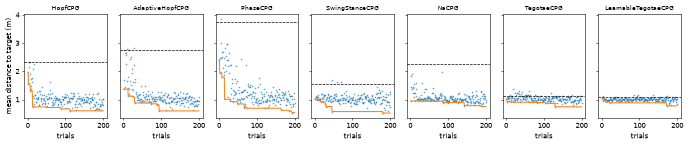

In [6]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(14, 3), sharey=True)
for ax, (name, (straight, scores, _)) in zip(
    axes, searches.items(), strict=True
):
    ax.plot(np.arange(1, BUDGET + 1), scores, ".", markersize=3, alpha=0.5)
    ax.plot(np.arange(1, BUDGET + 1), np.minimum.accumulate(scores))
    ax.axhline(straight, color="black", linestyle="--", linewidth=1)
    ax.set_title(name, fontsize=8)
    ax.set_xlabel("trials")
axes[0].set_ylabel("mean distance to target (m)")
fig.tight_layout()
plt.show()

## The test

Every CPG, steered and unsteered, on the same fresh pairs. For each run:

* mean: the score, the mean distance to the current target (m);
* final: the distance to B at 30 s (m);
* turn: the seconds after the jump until the core heads within 30 degrees
  of B, the heading being its displacement over the last 0.5 s (median over
  the pairs where it happens; how many did is in brackets).

In [7]:
TEST = np.random.default_rng(1).uniform(0, 2 * np.pi, size=(TEST_PAIRS, 2))
HEADING_WINDOW = 0.5  # seconds
HEADING_TOLERANCE = np.radians(30)
LAG = round(HEADING_WINDOW / (STEPS_PER_CONTROL * model.opt.timestep))


def turn_time(path, target):
    """Return the seconds after the jump until the core heads towards B.

    Returns
    -------
    float
        Seconds, or NaN if the heading never came within the tolerance.
    """
    times, xy = path[:-1, 0], path[:-1, 1:3]
    for k in range(LAG, len(times)):
        if times[k] < SWITCH + HEADING_WINDOW:
            continue
        heading = xy[k] - xy[k - LAG]
        towards = target - xy[k]
        angle = np.arctan2(
            heading[0] * towards[1] - heading[1] * towards[0], heading @ towards
        )
        if abs(angle) < HEADING_TOLERANCE:
            return float(times[k] - SWITCH)
    return float("nan")


class Run(FrozenModel):
    """One CPG, steered or not, on every test pair."""

    name: str
    steered: bool
    mean: list[float]
    final: list[float]
    turn: list[float]


paths = {}
runs = {}
for cpg_class in MODELS:
    name = cpg_class.__name__
    for steered in (False, True):
        params = searches[name][2] if steered else None
        rows = [trial(build(name, params), pair) for pair in TEST]
        paths[name, steered] = rows
        b = [
            targets_of(pair, path[0, 1:3])[1]
            for pair, path in zip(TEST, rows, strict=True)
        ]
        runs[name, steered] = Run(
            name=name,
            steered=steered,
            mean=[score(path) for path in rows],
            final=[float(path[-1, 3]) for path in rows],
            turn=list(starmap(turn_time, zip(rows, b, strict=True))),
        )


def summary(run):
    turns = np.array(run.turn)
    done = np.isfinite(turns)
    median = np.median(turns[done]) if done.any() else float("nan")
    return (
        f"{np.mean(run.mean):6.3f} {np.mean(run.final):6.3f}"
        f" {median:5.1f} ({done.sum()}/{len(turns)})"
    )


console.print(
    f"{'CPG':20s} {'s/trial':>7s}   {'unsteered: mean final turn':>28s}"
    f"   {'steered: mean final turn':>26s}"
)
for name in CLASSES:
    console.print(
        f"{name:20s} {seconds_per_trial[name]:7.2f}   "
        f"{summary(runs[name, False]):>28s}   {summary(runs[name, True]):>26s}"
    )
baseline = np.mean(runs[BASELINE, False].mean)
for label, bar in (("the baseline", baseline), ("standing still", RADIUS)):
    better = [name for name in CLASSES if np.mean(runs[name, True].mean) < bar]
    console.print(
        f"{label} scores {bar:.3f} m; steered CPGs below it:"
        f" {', '.join(better) if better else 'none'}"
    )

CPG                  s/trial     unsteered: mean final turn     steered: mean final turn

HopfCPG                 1.14      2.331  3.848   nan (0/10)    0.934  0.774   1.2 (10/10)

AdaptiveHopfCPG         1.29     2.894  4.376   1.3 (10/10)    0.976  1.057   0.6 (10/10)

PhaseCPG                1.16      3.892  7.154   nan (0/10)    1.030  0.984   1.3 (10/10)

SwingStanceCPG          1.24     1.704  2.246   1.9 (10/10)    0.986  1.122   1.3 (10/10)

NaCPG                   1.38     2.423  3.848   0.6 (10/10)    0.981  0.880   0.8 (10/10)

TegotaeCPG              1.27     1.181  1.109   0.8 (10/10)    1.003  1.020   1.1 (10/10)

LearnableTegotaeCPG     1.56     1.152  1.180   1.8 (10/10)    0.991  1.023   1.0 (10/10)

the baseline scores 3.892 m; steered CPGs below it: HopfCPG, AdaptiveHopfCPG, PhaseCPG, SwingStanceCPG, NaCPG, 
TegotaeCPG, LearnableTegotaeCPG

standing still scores 1.000 m; steered CPGs below it: HopfCPG, AdaptiveHopfCPG, SwingStanceCPG, NaCPG, 
LearnableTegotaeCPG

## Distance to the target over time

Mean over the test pairs of the distance to the current target; the target
jumps at 15 s (grey line). Solid: steered; dashed black: the baseline;
dotted: standing still.

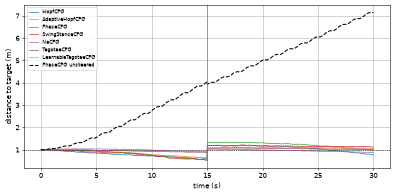

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in CLASSES:
    rows = paths[name, True]
    length = min(len(path) for path in rows) - 1
    mean = np.mean([path[:length, 3] for path in rows], axis=0)
    ax.plot(rows[0][:length, 0], mean, linewidth=1, label=name)
rows = paths[BASELINE, False]
length = min(len(path) for path in rows) - 1
ax.plot(
    rows[0][:length, 0],
    np.mean([path[:length, 3] for path in rows], axis=0),
    color="black",
    linestyle="--",
    label=f"{BASELINE} unsteered",
)
ax.axvline(SWITCH, color="grey", linewidth=1)
ax.axhline(RADIUS, color="black", linestyle=":", linewidth=1)
ax.set_xlabel("time (s)")
ax.set_ylabel("distance to target (m)")
ax.legend(fontsize=7)
ax.grid(visible=True)
fig.tight_layout()
plt.show()

## Paths

The best steered CPG (lowest mean test score) against the baseline on the
first four test pairs: the path to A in blue, after the jump in orange, A
and B as circles, the start as a cross.

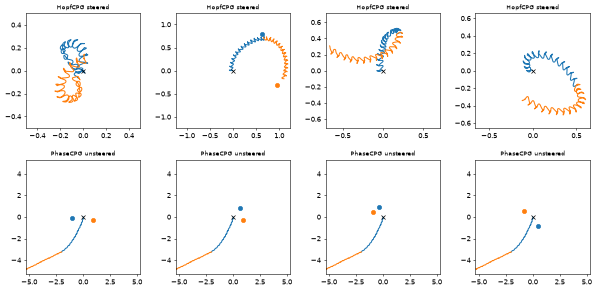

In [9]:
best_name = min(CLASSES, key=lambda name: np.mean(runs[name, True].mean))
shown = [(best_name, True), (BASELINE, False)]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row_axes, (name, steered) in zip(axes, shown, strict=True):
    for ax, pair, path in zip(
        row_axes, TEST, paths[name, steered], strict=False
    ):
        start = path[0, 1:3]
        a, b = targets_of(pair, start)
        before = path[:, 0] < SWITCH
        ax.plot(path[before, 1], path[before, 2], color="tab:blue")
        ax.plot(path[~before, 1], path[~before, 2], color="tab:orange")
        ax.plot(*a, "o", color="tab:blue")
        ax.plot(*b, "o", color="tab:orange")
        ax.plot(*start, "kx")
        ax.set_aspect("equal")
        half = max(0.5, np.abs(path[:, 1:3] - start).max() + 0.05)
        ax.set_xlim(start[0] - half, start[0] + half)
        ax.set_ylim(start[1] - half, start[1] + half)
        ax.set_title(
            f"{name} {'steered' if steered else 'unsteered'}", fontsize=8
        )
fig.tight_layout()
plt.show()

## Weights and videos

The gait and weights each search found go to `steered_<CPG>.json`. With OpenGL, the
best steered CPG and the baseline are filmed from above on the first test
pair (`steered_<CPG>_<time stamp>.mp4`, `baseline_<CPG>_<time stamp>.mp4`),
through the same `trial` that scored them; the frame at 25 s is shown.

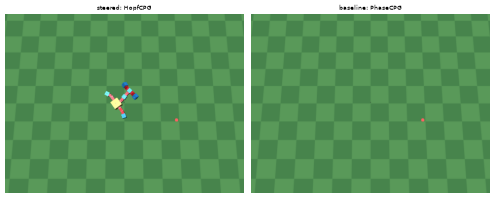

saved in /home/jmdm/projects/ariel/tests/functional/__data__/cpg_steering: baseline_PhaseCPG_20261022_133630.mp4, 
steered_AdaptiveHopfCPG.json, steered_HopfCPG.json, steered_HopfCPG_20261022_133622.mp4, 
steered_LearnableTegotaeCPG.json, steered_NaCPG.json, steered_PhaseCPG.json, steered_SwingStanceCPG.json, 
steered_TegotaeCPG.json

In [10]:
class Steering(FrozenModel):
    """The gait and steering weights one search found for one CPG."""

    cpg: str
    routes: list[InputRoute]
    params: list[float]
    test_mean: float


OUTPUT = DATA / "cpg_steering"
OUTPUT.mkdir(parents=True, exist_ok=True)
for name in CLASSES:
    record = Steering(
        cpg=name,
        routes=STEERING,
        params=[float(value) for value in searches[name][2]],
        test_mean=float(np.mean(runs[name, True].mean)),
    )
    (OUTPUT / f"steered_{name}.json").write_text(
        record.model_dump_json(indent=2)
    )

filmed = {}
stills = {}
if BACKEND is None:
    console.print("No working OpenGL backend: videos skipped.")
else:
    fps = round(1 / (STEPS_PER_FRAME * model.opt.timestep))
    for label, (name, steered) in zip(
        ("steered", "baseline"), shown, strict=True
    ):
        recorder = VideoRecorder(
            file_name=f"{label}_{name}",
            output_folder=OUTPUT,
            width=480,
            height=360,
            fps=fps,
        )
        frames = []

        def film(frame, recorder=recorder, frames=frames):
            recorder.write(frame)
            frames.append(frame)

        params = searches[name][2] if steered else None
        filmed[name, steered] = trial(build(name, params), TEST[0], film=film)
        recorder.release()
        stills[label, name] = frames[round(25 * fps)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, ((label, name), frame) in zip(axes, stills.items(), strict=True):
        ax.imshow(frame)
        ax.axis("off")
        ax.set_title(f"{label}: {name}", fontsize=8)
    fig.tight_layout()
    plt.show()
console.print(
    f"saved in {OUTPUT}: "
    + ", ".join(sorted(path.name for path in OUTPUT.iterdir()))
)

## Checks

The starting gaits must walk as far in 10 s as `cpg_locomotion` measured
(the marker changes nothing), the targets must lie on the circle, every
search must start from the straight gait, and replaying a test run, also
with the camera on, must give the same path.

In [11]:
SAME = 1e-6  # metres
for name in CLASSES:
    straight = trial(build(name), TEST[0], seconds=STRAIGHT_SECONDS)
    walked = np.linalg.norm(straight[-1, 1:3] - straight[0, 1:3])
    assert abs(walked - GAITS[name].distance) < SAME, name
    assert np.isfinite(searches[name][1]).all(), name
    for run in (runs[name, False], runs[name, True]):
        assert np.isfinite(run.mean).all(), name
        assert np.isfinite(run.final).all(), name
first = paths[BASELINE, False][0]
on_circle = np.linalg.norm(
    targets_of(TEST[0], first[0, 1:3]) - first[0, 1:3], axis=1
)
assert np.allclose(on_circle, RADIUS)
again = trial(build(best_name, searches[best_name][2]), TEST[0])
assert np.abs(again - paths[best_name, True][0]).max() < SAME
for (name, steered), path in filmed.items():
    assert np.abs(path - paths[name, steered][0]).max() < SAME, name
assert len(list(OUTPUT.glob("steered_*.json"))) == len(MODELS)